<a href="https://colab.research.google.com/github/vladislavpykhteev/HSE_Vladislav_Pykhteev/blob/main/final_practice/final_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏛️ Итоговый проект: Обзор судебной практики



## 1.Описание работы

**Источник данных:** [sudact.ru](https://sudact.ru) — открытая база судебных актов.


Ваша работа начинается с **исследовательского вопроса**. Выберите его сами — под вашу практику или интерес. Три ориентира (можно любой свой в том же духе):

| Профиль | Пример вопроса |
|---|---|
| **Практика по норме** | Как арбитражные суды применяют ст. 333 ГК РФ (снижение неустойки)? |
| **Практика по суду** | Чем занимается АС Московской области по договорам подряда? |
| **Практика по судье** | Портрет судьи: категории споров и динамика за 2023–2026 |

✍️ **Заполните паспорт** в ячейке ниже.

In [28]:
PASSPORT = {
    "ФИО": "Пыхтеев Владислав Сергеевич",
    "Профиль": "Практика по норме",
    "Исследовательский вопрос": "Как арбитражные суды применяют статью 333 ГК РФ при снижении неустойки?",
    "Поисковая фраза для sudact": "статья 333 ГК РФ неустойка",
    "Дополнительные фильтры": "арбитражные суды, документы за 2023–2025 годы",
    "Диапазон дат анализа": "01.01.2023–31.12.2025",
}
print("Паспорт работы:")
for key, value in PASSPORT.items():
    print(f"   {key}: {value}")

Паспорт работы:
   ФИО: Пыхтеев Владислав Сергеевич
   Профиль: Практика по норме
   Исследовательский вопрос: Как арбитражные суды применяют статью 333 ГК РФ при снижении неустойки?
   Поисковая фраза для sudact: статья 333 ГК РФ неустойка
   Дополнительные фильтры: арбитражные суды, документы за 2023–2025 годы
   Диапазон дат анализа: 01.01.2023–31.12.2025


## 3. Пайплайн работы

```
[1] ПОИСК        GET sudact.ru/arbitral/?arbitral-txt=<ваша фраза>  → список ссылок
       ↓
[2] СБОР         GET каждой карточки (пауза 1.5–2 с, try/except)    → HTML-страницы
       ↓
[3] РАЗБОР       BeautifulSoup: суд, судья, стороны, № дела, дата,
                 тип акта, полный текст                              → список словарей
       ↓
[4] БАЗА         SQLite: таблица acts (с PRIMARY KEY) + logs;        → practice.db
                 повторный запуск НЕ создаёт дублей
       ↓
[5] АНАЛИТИКА    SQL-запросы: по судам, годам, типам, исходам        → цифры для справки
       ↓
[6] ДОКУМЕНТЫ    Excel-таблица + Word-справка с выводами             → practice_report.xlsx
                                                                 practice_summary.docx
```

**Требование к объёму:** соберите не менее **15 документов**. Хотите больше — изучайте хоть сотни.

## Как строится оценка

Работа стоит **до 8 баллов**: четыре блока × до 2 баллов.

Каждый блок — **две строки оценки**: 🥉 базовый (1 балл) и 🥇 продвинутый (ещё 1 балл). Продвинутый засчитывается только поверх базового: несделанный базовый не компенсируется продвинутым.

Дополнительно баллы могут снижаться за оформление кода, синтаксические и логические ошибки.

---
# Блок 1. Сбор данных — до 2 баллов

| | Что проверяется | Балл |
|---|---|---|
| 🥉 | Поиск кодом: GET с вашими параметрами, собрано ≥15 ссылок; карточки скачиваются | **1** |
| 🥇 | Полная обработка ошибок, сбой одной не прерывает сбор остальных, упавшая помечается и пропускается | **+1** |


In [20]:
# 1.1 — Поиск: собираем ссылки на карточки решений
import hashlib
import json
import re
import sqlite3
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urljoin, urlparse

import pandas as pd
import requests
from bs4 import BeautifulSoup
from requests.exceptions import RequestException


BASE_URL = "https://sudact.ru"
SEARCH_URL = f"{BASE_URL}/arbitral/doc/"
SEARCH_AJAX_URL = f"{BASE_URL}/arbitral/doc_ajax/"
DATE_FROM = "01.01.2023"
DATE_TO = "31.12.2025"
DATE_FROM_ISO = "2023-01-01"
DATE_TO_ISO = "2025-12-31"
TARGET_DOCUMENTS = 30
CANDIDATES_PER_PERIOD = 8
MAX_SEARCH_PAGES = 3
REQUEST_TIMEOUT = 30
REQUEST_DELAY = 1.7
CACHE_DIR = Path("court_html_cache")
LINKS_CACHE_FILE = CACHE_DIR / "document_links.json"
USE_CACHE = True
REFRESH_CACHE = False
# Поиск Sudact буквальный: длинный запрос часто даёт 0 результатов.
# Поэтому используем короткие смысловые фразы, а наличие статьи 333
# обязательно проверяем уже по полному тексту каждой карточки.
SEARCH_QUERIES = [
    "снижение неустойки",
    "уменьшение неустойки",
    "333 ГК",
]

# Разбиваем общий диапазон на полугодия. Иначе Sudact, который сортирует
# документы от новых к старым, отдаёт почти только декабрь 2025 года.
SEARCH_PERIODS = [
    ("1-е полугодие 2023", "01.01.2023", "30.06.2023"),
    ("2-е полугодие 2023", "01.07.2023", "31.12.2023"),
    ("1-е полугодие 2024", "01.01.2024", "30.06.2024"),
    ("2-е полугодие 2024", "01.07.2024", "31.12.2024"),
    ("1-е полугодие 2025", "01.01.2025", "30.06.2025"),
    ("2-е полугодие 2025", "01.07.2025", "31.12.2025"),
]

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36"
    ),
    "Accept-Language": "ru-RU,ru;q=0.9",
})
run_logs = []

def add_log(stage, item_url, status, message=""):
    run_logs.append({
        "stage": stage,
        "item_url": item_url,
        "status": status,
        "message": str(message)[:500],
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    })


def get_with_retry(url, params=None, attempts=3):
    """GET с тремя попытками; ошибка одной страницы не роняет весь проект."""
    last_error = None
    for attempt in range(1, attempts + 1):
        try:
            response = session.get(url, params=params, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            response.encoding = response.apparent_encoding or "utf-8"

            lowered = response.text.lower()
            if "captcha" in lowered or "доступ ограничен" in lowered:
                raise ValueError("Sudact вернул страницу ограничения доступа")
            if len(response.text) < 1000:
                raise ValueError("Получена подозрительно короткая HTML-страница")
            return response
        except (RequestException, ValueError) as error:
            last_error = error
            if attempt < attempts:
                time.sleep(2 * attempt)
    raise last_error


def get_search_content(search_text, page_number, date_from, date_to):
    """Запускает асинхронный поиск Sudact и возвращает HTML с карточками.

    Обычный адрес /arbitral/doc/ содержит только оболочку страницы. Сами
    результаты браузер получает отдельными запросами к /arbitral/doc_ajax/.
    """
    search_params = {
        "arbitral-txt": search_text,
        "arbitral-case_doc": "",
        "arbitral-lawchunkinfo": "",
        "arbitral-date_from": date_from,
        "arbitral-date_to": date_to,
        "arbitral-region": "",
        "arbitral-court": "",
        "arbitral-judge": "",
    }
    if page_number > 1:
        search_params["page"] = page_number

    # Первый запрос создаёт поисковую сессию и cookie.
    prime_response = get_with_retry(SEARCH_URL, params=search_params)
    if urlparse(prime_response.url).path.rstrip("/") != "/arbitral/doc":
        raise ValueError(f"Неожиданный адрес поисковой страницы: {prime_response.url}")

    deadline = time.monotonic() + 25
    delay = 0.5
    last_status = "ожидание"

    while time.monotonic() < deadline:
        ajax_params = dict(search_params)
        ajax_params["_"] = int(time.time() * 1000)
        try:
            response = session.get(
                SEARCH_AJAX_URL,
                params=ajax_params,
                headers={
                    "X-Requested-With": "XMLHttpRequest",
                    "Referer": prime_response.url,
                },
                timeout=REQUEST_TIMEOUT,
            )
            response.raise_for_status()
            data = response.json()
        except (RequestException, ValueError) as error:
            raise ValueError(f"Ошибка асинхронного поиска Sudact: {error}") from error

        content = data.get("content") or ""
        last_status = data.get("search_status") or last_status
        if content:
            return content, data.get("total_found"), prime_response.url
        if last_status == "finished":
            return "", data.get("total_found"), prime_response.url

        time.sleep(delay)
        delay = min(delay * 1.3, 2.5)

    raise ValueError(f"Sudact не завершил поиск за 25 секунд, статус: {last_status}")


def find_document_links(html, page_url):
    """Находит ссылки на карточки и правильно обрабатывает относительные href."""
    soup = BeautifulSoup(html, "html.parser")
    found = []
    for link in soup.find_all("a", href=True):
        raw_href = str(link["href"]).strip()
        clean_href = raw_href.split("#", 1)[0].split("?", 1)[0]
        if not clean_href:
            continue

        # В выдаче встречаются как полные ссылки /arbitral/doc/<id>/,
        # так и относительные <id>/. Поэтому базой служит адрес выдачи,
        # а не только корень сайта https://sudact.ru.
        full_url = urljoin(page_url, clean_href)
        path = urlparse(full_url).path
        match = re.fullmatch(r"/arbitral/doc/([A-Za-z0-9_-]{6,})/?", path)

        # Дополнительный запасной вариант для короткой относительной ссылки.
        if not match:
            relative_match = re.fullmatch(
                r"(?:[.]/)?([A-Za-z0-9_-]{6,})/?",
                clean_href,
            )
            if relative_match:
                full_url = urljoin(SEARCH_URL, relative_match.group(1) + "/")
                match = re.fullmatch(
                    r"/arbitral/doc/([A-Za-z0-9_-]{6,})/?",
                    urlparse(full_url).path,
                )

        if match:
            # Убираем параметры и приводим адрес к единому виду с завершающим /.
            found.append(urljoin(SEARCH_URL, match.group(1) + "/"))
    return list(dict.fromkeys(found))


def search_cache_signature():
    """Параметры, при изменении которых старую подборку ссылок брать нельзя."""
    return {
        "date_from": DATE_FROM,
        "date_to": DATE_TO,
        "target_documents": TARGET_DOCUMENTS,
        "candidates_per_period": CANDIDATES_PER_PERIOD,
        "queries": SEARCH_QUERIES,
        # JSON превращает кортежи в списки; приводим заранее, чтобы подпись
        # совпадала и после чтения файла.
        "periods": [list(period) for period in SEARCH_PERIODS],
    }


def load_cached_links():
    if not USE_CACHE or REFRESH_CACHE or not LINKS_CACHE_FILE.exists():
        return []
    try:
        cached = json.loads(LINKS_CACHE_FILE.read_text(encoding="utf-8"))
        links = cached.get("links", [])
        if cached.get("signature") == search_cache_signature() and len(links) >= TARGET_DOCUMENTS:
            return links
    except (OSError, ValueError, TypeError):
        pass
    return []


def save_cached_links(document_links):
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    payload = {
        "signature": search_cache_signature(),
        "saved_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "links": document_links,
    }
    LINKS_CACHE_FILE.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


def html_cache_path(card_url):
    digest = hashlib.sha256(card_url.encode("utf-8")).hexdigest()
    return CACHE_DIR / f"{digest}.html"


def collect_document_links():
    cached_links = load_cached_links()
    if cached_links:
        print(
            f"Используется кэш поисковой выборки: {len(cached_links)} ссылок. "
            "Повторный запуск не обращается к поиску Sudact."
        )
        add_log("search_cache", str(LINKS_CACHE_FILE), "ok", f"Ссылок: {len(cached_links)}")
        return cached_links

    document_links = []
    for period_name, date_from, date_to in SEARCH_PERIODS:
        period_links = []
        print(f"\nПериод: {period_name} ({date_from}–{date_to})")

        for search_text in SEARCH_QUERIES:
            print(f"Поисковый запрос: {search_text}")

            for page_number in range(1, MAX_SEARCH_PAGES + 1):
                try:
                    content, total_found, search_url = get_search_content(
                        search_text,
                        page_number,
                        date_from,
                        date_to,
                    )
                    page_links = find_document_links(content, SEARCH_URL)
                    new_links = [
                        url for url in page_links
                        if url not in document_links and url not in period_links
                    ]
                    period_links.extend(new_links)
                    add_log(
                        "search",
                        search_url,
                        "ok",
                        (
                            f"Период: {period_name}; запрос: {search_text}; "
                            f"страница: {page_number}; новых ссылок: {len(new_links)}; "
                            f"всего найдено: {total_found}"
                        ),
                    )
                    print(
                        f"  Страница {page_number}: новых ссылок {len(new_links)}, "
                        f"для периода {len(period_links)}; Sudact сообщает: {total_found}"
                    )
                    if page_number == 1:
                        print("  Проверочный адрес:", search_url)

                    if page_number == 1 and not page_links:
                        break

                except (RequestException, ValueError) as error:
                    add_log("search", SEARCH_URL, "error", error)
                    print(f"  Ошибка {type(error).__name__}: {error}")
                    if page_number == 1:
                        break

                if len(period_links) >= CANDIDATES_PER_PERIOD:
                    break
                time.sleep(REQUEST_DELAY)

            if len(period_links) >= CANDIDATES_PER_PERIOD:
                break

        selected_period_links = period_links[:CANDIDATES_PER_PERIOD]
        document_links.extend(selected_period_links)
        print(f"Отобрано ссылок за период: {len(selected_period_links)}")

    if len(document_links) < TARGET_DOCUMENTS:
        raise RuntimeError(
            f"Найдено только {len(document_links)} ссылок; "
            f"для итоговой выборки нужно не менее {TARGET_DOCUMENTS}"
        )
    save_cached_links(document_links)
    print(f"Список ссылок сохранён в кэш: {LINKS_CACHE_FILE.resolve()}")
    return document_links

document_links = collect_document_links()
print(f"\nСобрано уникальных ссылок-кандидатов: {len(document_links)}")


Период: 1-е полугодие 2023 (01.01.2023–30.06.2023)
Поисковый запрос: снижение неустойки
  Страница 1: новых ссылок 10, для периода 10; Sudact сообщает: 


Найдено 2 006 документов
  Проверочный адрес: https://sudact.ru/arbitral/doc/?arbitral-txt=%D1%81%D0%BD%D0%B8%D0%B6%D0%B5%D0%BD%D0%B8%D0%B5+%D0%BD%D0%B5%D1%83%D1%81%D1%82%D0%BE%D0%B9%D0%BA%D0%B8&arbitral-case_doc=&arbitral-lawchunkinfo=&arbitral-date_from=01.01.2023&arbitral-date_to=30.06.2023&arbitral-region=&arbitral-court=&arbitral-judge=
Отобрано ссылок за период: 8

Период: 2-е полугодие 2023 (01.07.2023–31.12.2023)
Поисковый запрос: снижение неустойки
  Страница 1: новых ссылок 10, для периода 10; Sudact сообщает: 


Найден 2 351 документ
  Проверочный адрес: https://sudact.ru/arbitral/doc/?arbitral-txt=%D1%81%D0%BD%D0%B8%D0%B6%D0%B5%D0%BD%D0%B8%D0%B5+%D0%BD%D0%B5%D1%83%D1%81%D1%82%D0%BE%D0%B9%D0%BA%D0%B8&arbitral-case_doc=&arbitral-lawchunkinfo=&arbitral-date_from=01.07.2023&arbitral-date_to=31.12.2023&arbitral-region=&arbitr

In [21]:
# 1.2 — Сбор карточек: скачиваем каждую ссылку
def download_cards(document_links, use_cache=USE_CACHE, delay=True, attempts=3):
    download_results = []
    loaded_from_cache = 0
    loaded_from_site = 0
    for number, card_url in enumerate(document_links, start=1):
        cache_file = html_cache_path(card_url)
        try:
            html = ""
            source = "site"
            if use_cache and not REFRESH_CACHE and cache_file.exists():
                html = cache_file.read_text(encoding="utf-8")
                if len(html) < 1000:
                    html = ""
            if html:
                source = "cache"
                loaded_from_cache += 1
            else:
                response = get_with_retry(card_url, attempts=attempts)
                html = response.text
                loaded_from_site += 1
                if use_cache:
                    CACHE_DIR.mkdir(parents=True, exist_ok=True)
                    cache_file.write_text(html, encoding="utf-8")

            download_results.append({
                "url": card_url,
                "status": "ok",
                "html": html,
                "error": "",
                "source": source,
            })
            add_log("download", card_url, "ok", f"Источник: {source}; символов HTML: {len(html)}")
            print(f"[{number:02d}/{len(document_links):02d}] карточка получена ({source})")
        except (OSError, RequestException, ValueError) as error:
            download_results.append({
                "url": card_url,
                "status": "error",
                "html": "",
                "error": f"{type(error).__name__}: {error}",
                "source": "",
            })
            add_log("download", card_url, "error", error)
            print(f"[{number:02d}/{len(document_links):02d}] пропуск: {error}")
        if delay and download_results[-1]["source"] == "site":
            time.sleep(REQUEST_DELAY)
    print(f"Из кэша: {loaded_from_cache}; с сайта: {loaded_from_site}")
    return download_results

download_results = download_cards(document_links)
downloaded_count = sum(item["status"] == "ok" for item in download_results)
failed_downloads = len(download_results) - downloaded_count

print(f"\nКарточек скачано: {downloaded_count}")
print(f"Карточек со сбоем: {failed_downloads}")

# Дополнительная проверка устойчивости: битая ссылка не останавливает сбор
BROKEN_TEST_URL = "not-a-valid-sudact-url"
broken_test_result = download_cards(
    [BROKEN_TEST_URL],
    use_cache=False,
    delay=False,
    attempts=1,
)[0]
assert broken_test_result["status"] == "error"
print("Проверка пройдена: недоступная карточка записана как ошибка и пропущена.")

[01/48] карточка получена (site)
[02/48] карточка получена (site)
[03/48] карточка получена (site)
[04/48] карточка получена (site)
[05/48] карточка получена (site)
[06/48] карточка получена (site)
[07/48] карточка получена (site)
[08/48] карточка получена (site)
[09/48] карточка получена (site)
[10/48] карточка получена (site)
[11/48] карточка получена (site)
[12/48] карточка получена (site)
[13/48] карточка получена (site)
[14/48] карточка получена (site)
[15/48] карточка получена (site)
[16/48] карточка получена (site)
[17/48] карточка получена (site)
[18/48] карточка получена (site)
[19/48] карточка получена (site)
[20/48] карточка получена (site)
[21/48] карточка получена (site)
[22/48] карточка получена (site)
[23/48] карточка получена (site)
[24/48] карточка получена (site)
[25/48] карточка получена (site)
[26/48] карточка получена (site)
[27/48] карточка получена (site)
[28/48] карточка получена (site)
[29/48] карточка получена (site)
[30/48] карточка получена (site)
[31/48] ка

---
# Блок 2. Разбор и очистка — до 2 баллов

| | Что проверяется | Балл |
|---|---|---|
| 🥉 | Из каждой карточки извлечено **≥7 полей** (тип акта, дата, суд, судья, истцы, ответчики, номер дела, текст); извлечение оформлено **функцией** | **1** |
| 🥇 | Даты нормализованы в ISO (`ГГГГ-ММ-ДД`); грязные/пустые значения обрабатываются **без падения** — функция работает и на нестандартных карточках (нет судьи, нет даты) | **+1** |

In [22]:
# 2.1 — Функции разбора карточки: HTML → словарь полей
MONTHS = {
    "января": 1, "февраля": 2, "марта": 3, "апреля": 4,
    "мая": 5, "июня": 6, "июля": 7, "августа": 8,
    "сентября": 9, "октября": 10, "ноября": 11, "декабря": 12,
}

DATE_RE = re.compile(
    r"(?<!\d)(\d{1,2}[.]\d{1,2}[.]\d{4}|"
    r"\d{1,2}\s+(?:января|февраля|марта|апреля|мая|июня|июля|августа|"
    r"сентября|октября|ноября|декабря)\s+\d{4})(?!\d)",
    re.I,
)

CASE_RE = re.compile(r"[АA]\s?\d{1,3}[-–]\d{1,9}/\d{2,4}", re.I)

# (?!\s*[.,]\s*\d) не даёт принять статью 333.40 НК РФ за статью 333 ГК РФ.
ARTICLE_333_RE = re.compile(
    r"(?:ст(?:атья|атьи|атью|атьёй|атье|[.])\s*333"
    r"(?!\s*[.,]\s*\d)|333\s*(?:ГК\s*РФ|Гражданского\s+кодекса))",
    re.I,
)


def compact_text(value):
    return re.sub(r"\s+", " ", value or "").strip()


def normalize_date(value):
    value = compact_text(value).lower().replace(" г.", "").replace(" года", "")
    for date_format in ("%d.%m.%Y", "%Y-%m-%d"):
        try:
            return datetime.strptime(value, date_format).strftime("%Y-%m-%d")
        except ValueError:
            pass

    match = re.search(r"(\d{1,2})\s+([а-яё]+)\s+(\d{4})", value)
    if match:
        day, month_word, year = match.groups()
        month = MONTHS.get(month_word)
        if month:
            return f"{year}-{month:02d}-{int(day):02d}"
    return ""


def clean_section_value(value):
    value = re.sub(r"\(подробнее\)", "", value, flags=re.I)
    value = re.sub(r"\((?:судья|председательствующий)\)", "", value, flags=re.I)
    return compact_text(value).strip(" |;–-")


def extract_section(soup, labels):
    """Читает блоки Суд, Истцы, Ответчики и Судьи дела внизу карточки."""
    wanted = {label.lower().rstrip(":") for label in labels}

    for heading in soup.find_all(re.compile(r"^h[1-6]$")):
        heading_text = compact_text(heading.get_text(" ", strip=True)).lower().rstrip(":")
        if heading_text not in wanted:
            continue

        parts = []
        for node in heading.next_siblings:
            node_name = getattr(node, "name", None)
            if node_name and re.fullmatch(r"h[1-6]", node_name):
                break
            # У NavigableString тоже есть метод find(), но это обычный поиск
            # подстроки и он не принимает регулярное выражение. Ищем вложенный
            # заголовок только у настоящего HTML-тега (у него заполнено name).
            if node_name and node.find(re.compile(r"^h[1-6]$")):
                break

            if hasattr(node, "get_text"):
                text = node.get_text(" ", strip=True)
            else:
                text = str(node)

            text = clean_section_value(text)
            if text and text not in parts:
                parts.append(text)

        if parts:
            return "; ".join(parts)

    # Запасной разбор по строкам. Он помогает, если сайт поменял контейнеры,
    # но сохранил видимые заголовки «Истцы:», «Ответчики:» и т. п.
    lines = [compact_text(text) for text in soup.stripped_strings]
    all_headings = {
        "суд", "истец", "истцы", "заявитель", "заявители", "ответчик",
        "ответчики", "заинтересованное лицо", "заинтересованные лица",
        "судья", "судьи", "судьи дела",
    }
    for index, line in enumerate(lines):
        if line.lower().rstrip(":") not in wanted:
            continue
        parts = []
        for value in lines[index + 1:index + 12]:
            if value.lower().rstrip(":") in all_headings:
                break
            value = clean_section_value(value)
            if not value or value.lower() in {
                "печать документа", "отправить на e-mail", "сохранить в word",
                "получить ссылку на документ",
            }:
                break
            if value not in parts:
                parts.append(value)
        return "; ".join(parts)

    return ""


def extract_document_text(soup):
    """Отделяет сам судебный акт от меню и карточки реквизитов внизу."""
    for node in soup(["script", "style", "noscript", "header", "footer", "nav"]):
        node.decompose()

    lines = [compact_text(text) for text in soup.stripped_strings]
    lines = [text for text in lines if text]

    h1 = soup.find("h1")
    title = compact_text(h1.get_text(" ", strip=True)) if h1 else ""
    start = lines.index(title) + 1 if title in lines else 0

    # Внизу карточки Sudact начинаются отдельные служебные блоки реквизитов.
    stop = len(lines)
    for index in range(start, len(lines)):
        if lines[index].lower() in {"суд:", "истцы:", "ответчики:", "судьи дела:"}:
            stop = index
            break

    return "\n".join(lines[start:stop])


def extract_decision_date(document_text, case_match):
    """Берёт дату из шапки акта рядом с номером дела, а не из заголовка сайта."""
    if case_match:
        after_case = document_text[case_match.end():case_match.end() + 600]
        match = DATE_RE.search(after_case)
        if match:
            return normalize_date(match.group(1))

        before_case = document_text[max(0, case_match.start() - 400):case_match.start()]
        matches = list(DATE_RE.finditer(before_case))
        if matches:
            return normalize_date(matches[-1].group(1))

    # Запасной вариант: первая дата в начале текста документа.
    match = DATE_RE.search(document_text[:1500])
    return normalize_date(match.group(1)) if match else ""


def spaced(word):
    """РЕШИЛ и Р Е Ш И Л распознаются одним шаблоном, как на вебинаре №15."""
    return r"\s*".join(re.escape(letter) for letter in word)


def extract_resolution(text):
    matches = []
    for marker in ("РЕШИЛ", "ОПРЕДЕЛИЛ", "ПОСТАНОВИЛ"):
        matches.extend(re.finditer(spaced(marker), text, re.I))
    if not matches:
        return text[-3500:]
    last_match = max(matches, key=lambda match: match.start())
    return text[last_match.start():last_match.start() + 3500]


def extract_case_result(text):
    resolution = compact_text(extract_resolution(text)).lower()
    if re.search(r"удовлетворить\s+частично|частично\s+удовлетворить", resolution):
        return "требования удовлетворены частично"
    if re.search(r"(?:в удовлетворении|в иске).{0,100}отказать", resolution):
        return "в требованиях отказано"
    if "оставить без изменения" in resolution:
        return "оставлено без изменения"
    if re.search(r"(?:иск|требовани).{0,120}удовлетворить", resolution):
        return "требования удовлетворены"
    return "результат требует проверки"


def contexts_around_333(text, radius=1000):
    contexts = []
    for match in ARTICLE_333_RE.finditer(text):
        start = max(0, match.start() - radius)
        stop = min(len(text), match.end() + radius)
        contexts.append(text[start:stop])
    return "\n".join(contexts)


def extract_333_outcome(text):
    """Определяет результат применения статьи 333 по решающей формулировке.

    В апелляционных актах могут одновременно пересказываться позиции сторон,
    вывод первой инстанции и итог текущего суда. Поэтому мы собираем все явные
    признаки и берём последний по тексту: обычно именно он относится к выводу
    суда, а не к пересказу доводов.
    """
    context = compact_text(contexts_around_333(text)).lower()
    if not context:
        return "статья 333 не обнаружена"

    refusal_patterns = [
        r"(?:суд\s+)?(?:не\s+наход|не\s+усматрива).{0,120}основани.{0,180}"
        r"(?:применени.{0,50}(?:статьи|ст[.])\s*333|снижени|уменьшени)",
        r"основани.{0,180}(?:для\s+)?(?:применени.{0,50}(?:статьи|ст[.])\s*333|"
        r"снижени|уменьшени).{0,120}(?:не\s+имеется|не\s+имеются|нет|отсутств)",
        r"(?:неустойк|пен).{0,140}(?:не\s+подлежит|основани.{0,50}нет).{0,80}"
        r"(?:снижени|уменьшени)",
        r"(?:отказать|отказывает|отклонить|отклоняет).{0,220}"
        r"(?:снижени|уменьшени|статьи\s*333|ст[.]\s*333)",
        r"(?:ходатайств|заявлени).{0,180}(?:о\s+снижени|об\s+уменьшени).{0,180}"
        r"(?:отклон|не\s+подлежит\s+удовлетворению)",
    ]
    reduction_patterns = [
        r"(?:имеются|имеет).{0,80}основани.{0,180}"
        r"(?:применени.{0,50}(?:статьи|ст[.])\s*333|снижени|уменьшени)"
        r".{0,220}(?:снижени|уменьшени|\bдо\b)",
        r"(?:суд\s+)?(?:считает|признает|находит).{0,140}"
        r"(?:возможным|необходимым|обоснованным).{0,140}(?:снизить|уменьшить)",
        r"(?:неустойк|пен).{0,180}(?:подлежит\s+снижению|подлежит\s+уменьшению|"
        r"снижен[аоы]?|уменьшен[аоы]?)",
        r"(?:сниз\w*|сниж\w*|уменьш\w*).{0,140}(?:неустойк|пен).{0,220}\bдо\b",
        r"(?:применить|применяет|применил|применив).{0,120}"
        r"(?:статью\s*333|ст[.]\s*333).{0,220}(?:сниз\w*|сниж\w*|уменьш\w*)",
    ]

    signals = []
    for pattern in refusal_patterns:
        signals.extend((match.start(), "refusal") for match in re.finditer(pattern, context, re.S))
    for pattern in reduction_patterns:
        signals.extend((match.start(), "reduction") for match in re.finditer(pattern, context, re.S))

    if signals:
        last_result = max(signals, key=lambda item: item[0])[1]
        if last_result == "refusal":
            return "в снижении неустойки отказано"
        return "неустойка снижена"

    return "статья 333 применена, результат требует проверки"


MONEY_RE = (
    r"(\d{1,3}(?:[ \u00a0]\d{3})+(?:[.,]\d{1,2})?|"
    r"\d+(?:[.,]\d{1,2})?)\s*(?:руб(?:лей|ля|ль|[.])?)"
)


def money_to_float(value):
    """Преобразует запись вида «1 250 000,50» в число."""
    cleaned = re.sub(r"[ \u00a0]", "", value or "").replace(",", ".")
    try:
        return round(float(cleaned), 2)
    except ValueError:
        return None


def extract_penalty_amounts(text, outcome):
    """Ищет сумму неустойки до и после снижения в ближайшем контексте."""
    if outcome != "неустойка снижена":
        return None, None, None

    normalized = compact_text(text).lower()
    after_patterns = [
        rf"(?:сниз\w*|сниж\w*|уменьш\w*).{{0,180}}(?:неустойк|пен).{{0,220}}до\s+{MONEY_RE}",
        rf"(?:неустойк|пен).{{0,180}}(?:снижен[аоы]?|уменьшен[аоы]?).{{0,80}}до\s+{MONEY_RE}",
        rf"(?:сниз\w*|сниж\w*|уменьш\w*).{{0,220}}до\s+{MONEY_RE}",
    ]
    before_patterns = [
        rf"(?:размер|сумм[аы]).{{0,80}}(?:неустойк|пен).{{0,100}}(?:составляет|"
        rf"в\s+размере|в\s+сумме)?\s*{MONEY_RE}",
        rf"(?:неустойк|пен).{{0,100}}(?:в\s+размере|в\s+сумме|составляет)\s*{MONEY_RE}",
        rf"(?:заявлен[аоы]?|начислен[аоы]?|предъявлен[аоы]?).{{0,100}}"
        rf"(?:неустойк|пен).{{0,100}}{MONEY_RE}",
    ]

    after_values = []
    for pattern in after_patterns:
        after_values.extend(money_to_float(match.group(1)) for match in re.finditer(pattern, normalized, re.S))
    after_values = [value for value in after_values if value is not None]
    if not after_values:
        return None, None, None
    penalty_after = after_values[-1]

    before_values = []
    for pattern in before_patterns:
        before_values.extend(money_to_float(match.group(1)) for match in re.finditer(pattern, normalized, re.S))
    before_values = [value for value in before_values if value and value > penalty_after]
    if not before_values:
        return None, penalty_after, None

    # Обычно исходная (заявленная) сумма — наибольшая из найденных рядом сумм.
    penalty_before = max(before_values)
    reduction_percent = round((penalty_before - penalty_after) / penalty_before * 100, 1)
    return penalty_before, penalty_after, reduction_percent


def parse_card(html, url):
    soup = BeautifulSoup(html, "html.parser")

    # Сначала читаем структурированные блоки, пока дерево HTML не изменено.
    court = extract_section(soup, ["Суд"])
    plaintiffs = extract_section(soup, ["Истцы", "Истец", "Заявители", "Заявитель"])
    defendants = extract_section(
        soup,
        ["Ответчики", "Ответчик", "Заинтересованные лица", "Заинтересованное лицо"],
    )
    judge = extract_section(soup, ["Судьи дела", "Судья", "Судьи"])

    h1 = soup.find("h1")
    title = compact_text(h1.get_text(" ", strip=True)) if h1 else ""
    document_text = extract_document_text(soup)

    act_type_match = re.search(
        r"\b(решение|постановление|определение|судебный приказ)\b",
        title + "\n" + document_text[:1200],
        re.I,
    )
    case_match = CASE_RE.search(title + "\n" + document_text[:2500])
    decision_date = extract_decision_date(document_text, CASE_RE.search(document_text[:2500]))

    # Запасные варианты нужны, если нижний блок реквизитов отсутствует.
    if not court:
        court_match = re.search(
            r"(?:Арбитражный суд|арбитражного апелляционного суда|"
            r"арбитражный суд округа)[^\n]{3,180}",
            document_text[:1500],
            re.I,
        )
        court = compact_text(court_match.group(0)) if court_match else ""

    if not judge:
        judge_match = re.search(
            r"(?:судьи?|председательствующего)\s+"
            r"([А-ЯЁ][а-яё-]+\s+[А-ЯЁ][.]\s*[А-ЯЁ][.]|"
            r"[А-ЯЁ][.]\s*[А-ЯЁ][.]\s*[А-ЯЁ][а-яё-]+)",
            document_text,
        )
        judge = compact_text(judge_match.group(1)) if judge_match else ""

    mention_333 = len(ARTICLE_333_RE.findall(document_text))
    outcome = extract_333_outcome(document_text)
    penalty_before, penalty_after, reduction_percent = extract_penalty_amounts(
        document_text, outcome
    )
    result = {
        "url": url,
        "act_type": act_type_match.group(1).capitalize() if act_type_match else "",
        "decision_date": decision_date,
        "court": court,
        "judge": judge,
        "plaintiffs": plaintiffs,
        "defendants": defendants,
        "case_number": (
            re.sub(r"\s+", "", case_match.group(0)).replace("A", "А").replace("–", "-")
            if case_match else ""
        ),
        "full_text": document_text,
        "outcome": outcome,
        "case_result": extract_case_result(document_text),
        "penalty_before": penalty_before,
        "penalty_after": penalty_after,
        "reduction_percent": reduction_percent,
        "mention_333": mention_333,
        "text_length": len(document_text),
    }

    quality_fields = [
        result["act_type"], result["decision_date"], result["court"], result["judge"],
        result["plaintiffs"], result["defendants"], result["case_number"],
        result["full_text"],
    ]
    result["parse_quality"] = round(
        sum(bool(value) for value in quality_fields) / len(quality_fields) * 100,
        1,
    )
    return result


def validate_act(act):
    reasons = []
    if not (DATE_FROM_ISO <= act["decision_date"] <= DATE_TO_ISO):
        reasons.append("дата вне диапазона")
    if act["mention_333"] == 0:
        reasons.append("статья 333 ГК РФ не найдена")
    if act["text_length"] < 1000:
        reasons.append("слишком короткий текст")
    if not act["case_number"]:
        reasons.append("не найден номер дела")
    return reasons

# Короткий тест на типичную структуру HTML с текстовым переносом между тегами.
# Он сразу обнаружит ошибку в extract_section до обработки всех карточек.
_test_soup = BeautifulSoup(
    "<h3>Суд</h3>\n<div>Арбитражный суд тестового региона</div><h3>Истцы</h3>",
    "html.parser",
)
assert extract_section(_test_soup, ["Суд"]) == "Арбитражный суд тестового региона"
del _test_soup
print("Функции разбора загружены, контрольный тест пройден")

# Дополнительная проверка устойчивости: пустая карточка разбирается без падения
empty_act = parse_card("", "test://empty-card")
empty_card_reasons = validate_act(empty_act)
assert empty_act["text_length"] == 0
assert empty_card_reasons
print("Проверка пройдена: пустая карточка разобрана, причины отклонения:")
print("; ".join(empty_card_reasons))

Функции разбора загружены, контрольный тест пройден
Проверка пройдена: пустая карточка разобрана, причины отклонения:
дата вне диапазона; статья 333 ГК РФ не найдена; слишком короткий текст; не найден номер дела


In [23]:
# 2.2 — Массовый разбор и обязательная проверка выборки
def half_year_label(date_value):
    """Преобразует 2024-05-10 в метку 2024-П1, а 2024-09-10 — в 2024-П2."""
    year, month, _ = date_value.split("-")
    half = "П1" if int(month) <= 6 else "П2"
    return f"{year}-{half}"


def select_balanced_acts(valid_acts, target=TARGET_DOCUMENTS):
    """Отбирает до target актов равномерно по шести полугодиям."""
    period_order = [
        "2023-П1", "2023-П2", "2024-П1",
        "2024-П2", "2025-П1", "2025-П2",
    ]
    groups = {period: [] for period in period_order}
    for act in sorted(valid_acts, key=lambda row: row["decision_date"]):
        period = half_year_label(act["decision_date"])
        if period in groups:
            groups[period].append(act)

    base_quota, extra = divmod(target, len(period_order))
    selected = []
    remaining = []
    for index, period in enumerate(period_order):
        quota = base_quota + (1 if index < extra else 0)
        selected.extend(groups[period][:quota])
        remaining.extend(groups[period][quota:])

    # Если в каком-либо полугодии документов оказалось мало, добираем
    # недостающее количество из остальных периодов.
    if len(selected) < target:
        remaining = sorted(remaining, key=lambda row: row["decision_date"])
        selected.extend(remaining[:target - len(selected)])

    return sorted(selected[:target], key=lambda row: row["decision_date"])


def parse_and_validate(download_results):
    valid_acts = []
    rejected_rows = []

    for item in download_results:
        if item["status"] != "ok":
            continue
        try:
            act = parse_card(item["html"], item["url"])
            reasons = validate_act(act)
            if reasons:
                rejected_rows.append({
                    "url": item["url"],
                    "decision_date": act["decision_date"],
                    "case_number": act["case_number"],
                    "reasons": "; ".join(reasons),
                })
                add_log("validate", item["url"], "rejected", "; ".join(reasons))
            else:
                valid_acts.append(act)
                add_log("parse", item["url"], "ok", f"Качество: {act['parse_quality']}%")
        except (AttributeError, KeyError, TypeError, ValueError) as error:
            add_log("parse", item["url"], "error", error)
            rejected_rows.append({
                "url": item["url"],
                "decision_date": "",
                "case_number": "",
                "reasons": f"ошибка разбора: {type(error).__name__}: {error}",
            })
            print(f"Не удалось разобрать {item['url']}: {error}")

    acts = select_balanced_acts(valid_acts)
    rejected_table = pd.DataFrame(rejected_rows)
    if len(acts) < TARGET_DOCUMENTS:
        raise RuntimeError(
            f"После проверки осталось {len(acts)} подходящих актов. "
            f"Для итоговой выборки нужно {TARGET_DOCUMENTS}. "
            "Увеличьте CANDIDATES_PER_PERIOD или проверьте таблицу rejected_table."
        )

    acts_table = pd.DataFrame(acts)
    acts_table.attrs["valid_before_selection"] = len(valid_acts)
    acts_table.attrs["not_selected_due_to_limit"] = len(valid_acts) - len(acts)
    acts_table.attrs["downloaded_ok"] = sum(
        item["status"] == "ok" for item in download_results
    )
    return acts, acts_table, rejected_table

acts, acts_table, rejected_table = parse_and_validate(download_results)

print(f"\nКарточек успешно скачано: {acts_table.attrs['downloaded_ok']}")
print(f"Прошло содержательную проверку: {acts_table.attrs['valid_before_selection']}")
print(f"Отклонено при проверке: {len(rejected_table)}")
print(
    f"Не вошло из-за лимита {TARGET_DOCUMENTS}: "
    f"{acts_table.attrs['not_selected_due_to_limit']}"
)
print(f"Отобрано в итоговую выборку: {len(acts_table)}")

# Маленькие тесты показывают, что регулярка отличает ГК РФ от НК РФ.
assert ARTICLE_333_RE.search("согласно статье 333 ГК РФ")
assert ARTICLE_333_RE.search("применить ст.333 ГК РФ")
assert not ARTICLE_333_RE.search("статья 333.40 НК РФ")
assert normalize_date("14 апреля 2025 года") == "2025-04-14"
assert extract_333_outcome(
    "Суд установил, что имеются основания для применения статьи 333 ГК РФ "
    "и снижения неустойки до 100 000 рублей."
) == "неустойка снижена"
assert extract_333_outcome(
    "Суд не находит оснований для применения ст. 333 ГК РФ."
) == "в снижении неустойки отказано"

display_columns = [
    "decision_date", "case_number", "act_type", "court", "judge",
    "plaintiffs", "defendants", "outcome", "case_result",
    "penalty_before", "penalty_after", "reduction_percent",
    "mention_333", "parse_quality", "url",
]
display_column_names = dict([
    ("decision_date", "Дата решения"),
    ("case_number", "Номер дела"),
    ("act_type", "Вид судебного акта"),
    ("court", "Суд"),
    ("judge", "Судья"),
    ("plaintiffs", "Истцы / заявители"),
    ("defendants", "Ответчики"),
    ("outcome", "Результат применения статьи 333 ГК РФ"),
    ("case_result", "Общий итог дела"),
    ("penalty_before", "Неустойка до снижения, руб."),
    ("penalty_after", "Неустойка после снижения, руб."),
    ("reduction_percent", "Снижение, %"),
    ("mention_333", "Упоминаний статьи 333"),
    ("parse_quality", "Заполненность реквизитов, %"),
    ("url", "Ссылка на судебный акт"),
])


def number_rows(table):
    """Добавляет отображаемую нумерацию строк, начиная с единицы."""
    table_for_display = table.copy()
    table_for_display.index = range(1, len(table_for_display) + 1)
    table_for_display.index.name = "№"
    return table_for_display


display(number_rows(
    acts_table[display_columns].rename(columns=display_column_names)
))

if not rejected_table.empty:
    print("Первые отклонённые карточки:")
    rejected_column_names = dict([
        ("url", "Ссылка на судебный акт"),
        ("decision_date", "Дата решения"),
        ("case_number", "Номер дела"),
        ("reasons", "Причина отклонения"),
    ])
    display(number_rows(
        rejected_table.head(10).rename(columns=rejected_column_names)
    ))

# Контрольные проверки: при неверной выборке следующие блоки не запускаются.
assert len(acts_table) >= TARGET_DOCUMENTS, (
    f"В итоговой выборке меньше {TARGET_DOCUMENTS} документов"
)
assert acts_table["decision_date"].between("2023-01-01", "2025-12-31").all(), (
    "Обнаружены документы вне выбранного периода"
)
assert acts_table["mention_333"].ge(1).all(), (
    "Есть документы без статьи 333 ГК РФ"
)
assert set(["2023", "2024", "2025"]).issubset(
    set(acts_table["decision_date"].str[:4])
), "В итоговой выборке представлены не все годы 2023–2025"

print("\nВсе обязательные проверки пройдены")
print(
    "Фактический период:",
    acts_table["decision_date"].min(),
    "—",
    acts_table["decision_date"].max(),
)
print("Распределение итоговой выборки по полугодиям:")
display(
    number_rows(
        acts_table["decision_date"]
        .map(half_year_label)
        .value_counts()
        .sort_index()
        .rename_axis("Полугодие")
        .reset_index(name="Документов")
    )
)
print("Результаты применения статьи 333 ГК РФ:")
display(
    number_rows(
        acts_table["outcome"]
        .value_counts(dropna=False)
        .rename_axis("Результат")
        .reset_index(name="Документов")
    )
)

print("Пустые значения в основных реквизитах:")
display(
    acts_table[
        ["decision_date", "case_number", "act_type", "court", "judge", "plaintiffs", "defendants"]
    ]
    .eq("")
    .sum()
    .rename(index=display_column_names)
    .rename("Пустых значений")
    .to_frame()
)


Карточек успешно скачано: 48
Прошло содержательную проверку: 43
Отклонено при проверке: 5
Не вошло из-за лимита 30: 13
Отобрано в итоговую выборку: 30


,Дата решения,Номер дела,Вид судебного акта,Суд,Судья,Истцы / заявители,Ответчики,Результат применения статьи 333 ГК РФ,Общий итог дела,"Неустойка до снижения, руб.","Неустойка после снижения, руб.","Снижение, %",Упоминаний статьи 333,"Заполненность реквизитов, %",Ссылка на судебный акт
№,,,,,,,,,,,,,,,
1,2023-06-28,А46-3942/2023,Решение,АС Омской области,Ухова Л.Д.,"АО ""ОМСКИЕ РАСПРЕДЕЛИТЕЛЬНЫЕ ТЕПЛОВЫЕ СЕТИ"" (И...","ПАО АКЦИОНЕРНЫЙ КОММЕРЧЕСКИЙ БАНК ""АК БАРС"" (И...",неустойка снижена,результат требует проверки,NaN,NaN,NaN,5,100.0,https://sudact.ru/arbitral/doc/yBcgpOFZRq5H/
2,2023-06-29,А46-14315/2022,Постановление,ФАС ЗСО (ФАС Западно-Сибирского округа),Забоев К.И.,"ООО ""ТАНЗАНИТ"" (ИНН: 6681006642)","ООО ""ИМПЕРИЯ"" (ИНН: 5528032666)",неустойка снижена,оставлено без изменения,NaN,NaN,NaN,6,100.0,https://sudact.ru/arbitral/doc/2Wza2Iiy5CUB/
3,2023-07-03,А05-14099/2022,Постановление,14 ААС (Четырнадцатый арбитражный апелляционны...,Холминов А.А.,"ООО ""ТГК-2 ЭНЕРГОСБЫТ""",ИП Леонтьев Евгений Геннадьевич,неустойка снижена,оставлено без изменения,NaN,NaN,NaN,2,100.0,https://sudact.ru/arbitral/doc/jzljd0VhaC1a/
4,2023-07-04,А40-106821/2023,Решение,АС города Москвы,Жбанковой Ю.В.,"ПАО ""Новолипецкий металлургический комбинат""","ОАО ""РОССИЙСКИЕ ЖЕЛЕЗНЫЕ ДОРОГИ""",неустойка снижена,в требованиях отказано,NaN,3000000.00,NaN,14,100.0,https://sudact.ru/arbitral/doc/Qq1rq7zwzUYK/
5,2023-07-06,А12-4913/2023,Решение,АС Волгоградской области,Карсаковым А.А.,Департамент муниципального имущества администр...,,неустойка снижена,в требованиях отказано,48808.00,500.00,99.0,8,87.5,https://sudact.ru/arbitral/doc/nF6SbCz6LkLJ/
6,2023-07-18,А50-10405/2023,Решение,АС Пермского края,Самаркин В.В.,"ООО ""МКС"" (ИНН: 3255049294)","ООО ""СЭС АНСЕР"" (ИНН: 5905062997)",в снижении неустойки отказано,требования удовлетворены,NaN,NaN,NaN,12,100.0,https://sudact.ru/arbitral/doc/jathRmyLNsrV/
7,2023-07-28,А40-86256/2023,Решение,АС города Москвы,,"ООО ""Терра-Транс""","АО ""ЭНИКАРГО""",в снижении неустойки отказано,результат требует проверки,NaN,NaN,NaN,5,87.5,https://sudact.ru/arbitral/doc/Gzr6vZfWNiWp/
8,2023-08-08,А08-4874/2022,Решение,АС Белгородской области,Иванова Л.Л.,"АО ""ЛЕБЕДИНСКИЙ ГОРНО-ОБОГАТИТЕЛЬНЫЙ КОМБИНАТ""","ООО ""Уральский ТРАНЗИТ""",в снижении неустойки отказано,требования удовлетворены,NaN,NaN,NaN,4,100.0,https://sudact.ru/arbitral/doc/VHX0YBWSqPQ9/
9,2023-10-04,А73-12846/2023,Постановление,АС Хабаровского края,ФИО1,"ООО ""Тимлюйский завод""","ОАО ""РЖД""",неустойка снижена,оставлено без изменения,NaN,NaN,NaN,3,100.0,https://sudact.ru/arbitral/doc/vzvkH1lYzRL1/


Первые отклонённые карточки:


,Ссылка на судебный акт,Дата решения,Номер дела,Причина отклонения
№,,,,
1,https://sudact.ru/arbitral/doc/8zvhg8QKXH6p/,2024-06-28,А07-30820/2023,статья 333 ГК РФ не найдена
2,https://sudact.ru/arbitral/doc/svaORNLxOgNw/,2024-12-28,А32-31771/2024,статья 333 ГК РФ не найдена
3,https://sudact.ru/arbitral/doc/PakKjBw2gNbK/,2025-06-28,А29-3879/2025,статья 333 ГК РФ не найдена
4,https://sudact.ru/arbitral/doc/ofph1hxiP66T/,2026-02-25,А40-292495/25,дата вне диапазона
5,https://sudact.ru/arbitral/doc/hXjMIb6QGPZQ/,2026-02-03,А40-237418/25,дата вне диапазона



Все обязательные проверки пройдены
Фактический период: 2023-06-28 — 2025-12-30
Распределение итоговой выборки по полугодиям:


,Полугодие,Документов
№,,
1,2023-П1,2
2,2023-П2,8
3,2024-П1,5
4,2024-П2,5
5,2025-П1,5
6,2025-П2,5


Результаты применения статьи 333 ГК РФ:


,Результат,Документов
№,,
1,неустойка снижена,21
2,в снижении неустойки отказано,8
3,"статья 333 применена, результат требует проверки",1


Пустые значения в основных реквизитах:


,Пустых значений
Дата решения,0
Номер дела,0
Вид судебного акта,0
Суд,0
Судья,4
Истцы / заявители,2
Ответчики,3


---
# Блок 3. База и аналитика — до 2 баллов

| | Что проверяется | Балл |
|---|---|---|
| 🥉 | Данные сохраняются в SQLite; к базе есть запросы | **1** |
| 🥇 | Таблица `acts` с **PRIMARY KEY** (например, url) + таблица `logs`; повторный запуск ноутбука **не создаёт дублей** (проверяется дважды запущенным Run All); **≥4 запроса-вопроса** — ответы цифрами, каждый приближает к выводу справки, а не «SELECT * ради галочки» | **+1** |

In [24]:
# 3.1 — Сохранение в SQLite и журнал запусков
DB_FILE = Path("practice.db")


def ensure_column(connection, table_name, column_name, column_type):
    """Добавляет новый столбец при открытии базы из предыдущей версии проекта."""
    existing = {
        row[1] for row in connection.execute(f"PRAGMA table_info({table_name})")
    }
    if column_name not in existing:
        connection.execute(
            f"ALTER TABLE {table_name} ADD COLUMN {column_name} {column_type}"
        )


with sqlite3.connect(DB_FILE) as connection:
    connection.execute("""
        CREATE TABLE IF NOT EXISTS runs (
            run_id INTEGER PRIMARY KEY AUTOINCREMENT,
            started_at TEXT NOT NULL,
            finished_at TEXT,
            target_documents INTEGER,
            downloaded_ok INTEGER,
            valid_before_selection INTEGER,
            selected_count INTEGER,
            rejected_count INTEGER
        )
    """)
    connection.execute("""
        CREATE TABLE IF NOT EXISTS acts (
            url TEXT PRIMARY KEY,
            act_type TEXT,
            decision_date TEXT,
            court TEXT,
            judge TEXT,
            plaintiffs TEXT,
            defendants TEXT,
            case_number TEXT,
            outcome TEXT,
            case_result TEXT,
            penalty_before REAL,
            penalty_after REAL,
            reduction_percent REAL,
            mention_333 INTEGER,
            text_length INTEGER,
            parse_quality REAL,
            full_text TEXT,
            collected_at TEXT,
            run_id INTEGER
        )
    """)
    connection.execute("""
        CREATE TABLE IF NOT EXISTS logs (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            run_id INTEGER,
            stage TEXT,
            item_url TEXT,
            status TEXT,
            message TEXT,
            created_at TEXT
        )
    """)

    # Миграция нужна, если в Colab остался practice.db от прежнего запуска.
    for column_name, column_type in [
        ("case_result", "TEXT"),
        ("penalty_before", "REAL"),
        ("penalty_after", "REAL"),
        ("reduction_percent", "REAL"),
        ("run_id", "INTEGER"),
    ]:
        ensure_column(connection, "acts", column_name, column_type)
    ensure_column(connection, "logs", "run_id", "INTEGER")

    started_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    cursor = connection.execute("""
        INSERT INTO runs (
            started_at, target_documents, downloaded_ok,
            valid_before_selection, selected_count, rejected_count
        ) VALUES (?, ?, ?, ?, ?, ?)
    """, (
        started_at,
        TARGET_DOCUMENTS,
        acts_table.attrs["downloaded_ok"],
        acts_table.attrs["valid_before_selection"],
        len(acts),
        len(rejected_table),
    ))
    run_id = cursor.lastrowid

    # Счётчик снимается ДО очистки и записи — теперь его смысл однозначен.
    count_before_write = connection.execute(
        "SELECT COUNT(*) FROM acts"
    ).fetchone()[0]
    existing_urls_before = {
        row[0] for row in connection.execute("SELECT url FROM acts")
    }

    # Явная проверка дублей, запрошенная в критериях проверки базы.
    duplicates_before = pd.read_sql_query("""
        SELECT url, COUNT(*) AS copies
        FROM acts
        GROUP BY url
        HAVING COUNT(*) > 1
    """, connection)

    current_urls = [act["url"] for act in acts]
    placeholders = ",".join("?" for _ in current_urls)
    removed_old_acts = connection.execute(
        f"DELETE FROM acts WHERE url NOT IN ({placeholders})",
        current_urls,
    ).rowcount

    collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
    for act in acts:
        connection.execute("""
            INSERT INTO acts (
                url, act_type, decision_date, court, judge, plaintiffs, defendants,
                case_number, outcome, case_result, penalty_before, penalty_after,
                reduction_percent, mention_333, text_length, parse_quality,
                full_text, collected_at, run_id
            ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
            ON CONFLICT(url) DO UPDATE SET
                act_type = excluded.act_type,
                decision_date = excluded.decision_date,
                court = excluded.court,
                judge = excluded.judge,
                plaintiffs = excluded.plaintiffs,
                defendants = excluded.defendants,
                case_number = excluded.case_number,
                outcome = excluded.outcome,
                case_result = excluded.case_result,
                penalty_before = excluded.penalty_before,
                penalty_after = excluded.penalty_after,
                reduction_percent = excluded.reduction_percent,
                mention_333 = excluded.mention_333,
                text_length = excluded.text_length,
                parse_quality = excluded.parse_quality,
                full_text = excluded.full_text,
                collected_at = excluded.collected_at,
                run_id = excluded.run_id
        """, (
            act["url"], act["act_type"], act["decision_date"], act["court"],
            act["judge"], act["plaintiffs"], act["defendants"],
            act["case_number"], act["outcome"], act["case_result"],
            act["penalty_before"], act["penalty_after"], act["reduction_percent"],
            act["mention_333"], act["text_length"], act["parse_quality"],
            act["full_text"], collected_at, run_id,
        ))

    for log in run_logs:
        connection.execute("""
            INSERT INTO logs (
                run_id, stage, item_url, status, message, created_at
            ) VALUES (?, ?, ?, ?, ?, ?)
        """, (
            run_id, log["stage"], log["item_url"], log["status"],
            log["message"], log["created_at"],
        ))

    duplicates_after = pd.read_sql_query("""
        SELECT url, COUNT(*) AS copies
        FROM acts
        GROUP BY url
        HAVING COUNT(*) > 1
    """, connection)
    count_after_write = connection.execute(
        "SELECT COUNT(*) FROM acts"
    ).fetchone()[0]
    connection.execute(
        "UPDATE runs SET finished_at = ? WHERE run_id = ?",
        (datetime.now(timezone.utc).isoformat(timespec="seconds"), run_id),
    )
    connection.commit()

connection.close()
new_unique_acts = sum(url not in existing_urls_before for url in current_urls)
updated_acts = len(current_urls) - new_unique_acts

print(f"База сохранена: {DB_FILE.resolve()}")
print(f"Номер запуска в журнале: {run_id}")
print(f"Актов до очистки и записи: {count_before_write}")
print(f"Удалено актов вне текущей выборки: {removed_old_acts}")
print(f"Добавлено новых URL: {new_unique_acts}")
print(f"Обновлено существующих URL: {updated_acts}")
print(f"Актов после записи: {count_after_write}")
print(f"Дублей до записи: {len(duplicates_before)}; после записи: {len(duplicates_after)}")
if not duplicates_after.empty:
    display(number_rows(duplicates_after.rename(columns={
        "url": "Ссылка",
        "copies": "Количество копий",
    })))

База сохранена: /content/practice.db
Номер запуска в журнале: 1
Актов до очистки и записи: 0
Удалено актов вне текущей выборки: 0
Добавлено новых URL: 30
Обновлено существующих URL: 0
Актов после записи: 30
Дублей до записи: 0; после записи: 0


---
### Вопрос 1. Каков объём и период выборки?

> **Краткий ответ:** В выборке 30 судебных актов из 20 судов за период с 28.06.2023 по 30.12.2025. Средняя заполненность реквизитов — 96.3%.


,Количество документов,Количество судов,Начало периода,Конец периода,"Средняя заполненность реквизитов, %"
№,,,,,
1,30,20,2023-06-28,2025-12-30,96.3


---
### Вопрос 2. Какие суды чаще встречаются в выборке?

> **Краткий ответ:** Чаще всего встречается АС города Москвы — 5 актов.


,Суд,Количество документов
№,,
1,АС города Москвы,5
2,АС Иркутской области,3
3,АС Хабаровского края,3
4,АС Кировской области,2
5,АС Омской области,2
6,14 ААС (Четырнадцатый арбитражный апелляционны...,1
7,9 ААС (Девятый арбитражный апелляционный суд),1
8,АС Белгородской области,1
9,АС Волгоградской области,1


---
### Вопрос 3. Как документы распределились по годам?

> **Краткий ответ:** Наибольшее количество документов одинаково в 2025, 2024 и 2023 годах — по 10 актов.


...

,Вид судебного акта,Количество документов
№,,
1,Решение,25
2,Постановление,5


---
### Вопрос 5. Как распределились результаты применения статьи 333 ГК РФ?

> **Краткий ответ:** Снижение установлено в 21 актах, отказ — в 8. Явный результат определён для 29 из 30 документов.


,Результат применения статьи 333 ГК РФ,Количество документов
№,,
1,неустойка снижена,21
2,в снижении неустойки отказано,8
3,"статья 333 применена, результат требует проверки",1


---
### Вопрос 6. Как изменилась сумма неустойки после применения статьи 333 ГК РФ?

> **Краткий ответ:** Пара «до → после» найдена для 5 актов; среднее снижение — 62.6%.


,Номер дела,Суд,"Неустойка до снижения, руб.","Неустойка после снижения, руб.","Снижение, %",Ссылка
№,,,,,,
1,А12-4913/2023,АС Волгоградской области,48808.00,500.00,99.0,https://sudact.ru/arbitral/doc/nF6SbCz6LkLJ/
2,А46-14908/2023,АС Омской области,37883.00,4135.00,89.1,https://sudact.ru/arbitral/doc/sL2FPXx00Vmb/
3,А70-1905/2025,АС Тюменской области,3106729.23,621345.84,80.0,https://sudact.ru/arbitral/doc/0przBalYGbxK/
4,А40-87295/2024,АС города Москвы,14000.00,9817.69,29.9,https://sudact.ru/arbitral/doc/NnKcEMqviqZX/
5,А73-2158/2024,АС Хабаровского края,202130.00,171811.00,15.0,https://sudact.ru/arbitral/doc/MUUfAskNbQN/


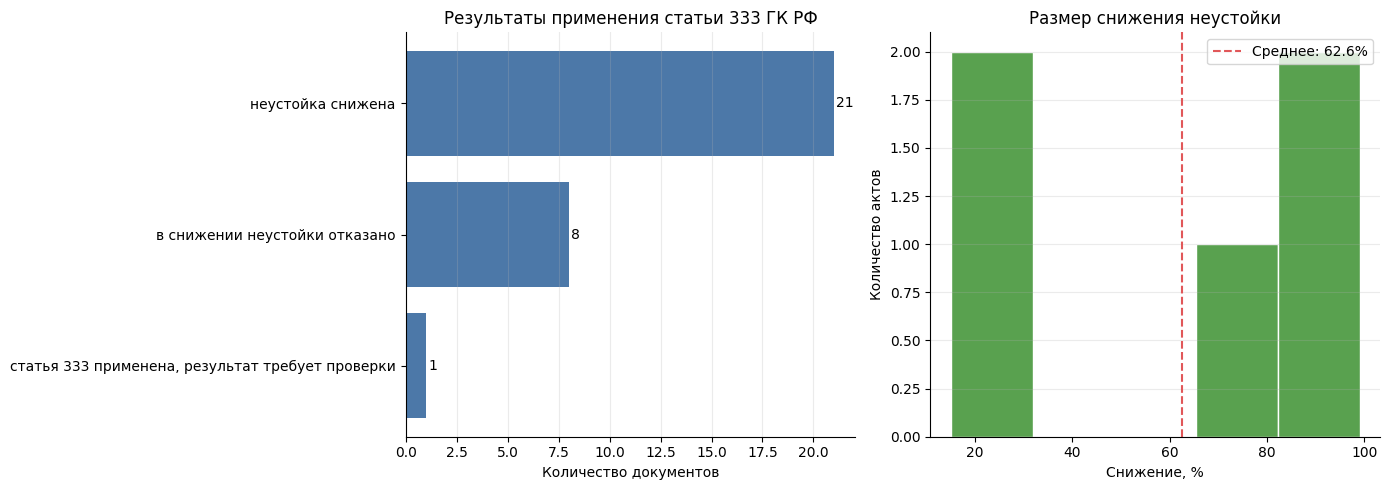

На карту нанесено судов: 8 из 20
Интерактивная карта сохранена: /content/court_map.html


In [25]:
# 3.2 — Аналитика: ≥4 вопроса к базе, ответы цифрами
from IPython.display import Markdown, display


def sql_table(query, params=()):
    connection = sqlite3.connect(DB_FILE)
    try:
        return pd.read_sql_query(query, connection, params=params)
    finally:
        connection.close()


def display_question(number, question, answer):
    """Выводит вопрос и короткий ответ как заметный раздел мини-отчёта."""
    display(Markdown(
        f"""---
### Вопрос {number}. {question}

> **Краткий ответ:** {answer}
"""
    ))


def format_date(date_value):
    """Переводит дату из формата базы в привычный формат ДД.ММ.ГГГГ."""
    parsed_date = pd.to_datetime(date_value, errors="coerce")
    return parsed_date.strftime("%d.%m.%Y") if not pd.isna(parsed_date) else "нет данных"


def year_distribution_answer(table):
    """Формирует ответ и правильно учитывает несколько лет с одинаковым максимумом."""
    if table.empty:
        return "Для распределения по годам недостаточно данных."

    ordered_table = table.sort_values(
        ["documents", "year"], ascending=[False, False]
    )
    maximum = int(ordered_table.iloc[0]["documents"])
    leading_years = (
        ordered_table.loc[ordered_table["documents"] == maximum, "year"]
        .astype(str)
        .tolist()
    )

    if len(leading_years) == 1:
        return (
            f"Больше всего документов относится к {leading_years[0]} году — "
            f"{maximum} актов."
        )

    if len(leading_years) == 2:
        years_text = " и ".join(leading_years)
    else:
        years_text = ", ".join(leading_years[:-1]) + " и " + leading_years[-1]

    return (
        f"Наибольшее количество документов одинаково в {years_text} годах — "
        f"по {maximum} актов."
    )


def display_table(table, column_names):
    """Показывает таблицу с понятными заголовками и нумерацией строк с единицы."""
    table_for_display = table.rename(columns=column_names).copy()
    table_for_display.index = range(1, len(table_for_display) + 1)
    table_for_display.index.name = "№"
    display(table_for_display)

# Вопрос 1 — какой размер и период у нашей выборки
sample_overview = sql_table("""
    SELECT
        COUNT(*) AS documents,
        COUNT(DISTINCT court) AS courts,
        MIN(decision_date) AS date_from,
        MAX(decision_date) AS date_to,
        ROUND(AVG(parse_quality), 1) AS avg_parse_quality
    FROM acts
""")
display_question(
    1,
    "Каков объём и период выборки?",
    (
        f"В выборке {int(sample_overview.loc[0, 'documents'])} судебных актов "
        f"из {int(sample_overview.loc[0, 'courts'])} судов за период "
        f"с {format_date(sample_overview.loc[0, 'date_from'])} "
        f"по {format_date(sample_overview.loc[0, 'date_to'])}. "
        f"Средняя заполненность реквизитов — "
        f"{float(sample_overview.loc[0, 'avg_parse_quality']):.1f}%."
    ),
)
display_table(sample_overview, {
    "documents": "Количество документов",
    "courts": "Количество судов",
    "date_from": "Начало периода",
    "date_to": "Конец периода",
    "avg_parse_quality": "Средняя заполненность реквизитов, %",
})

# Вопрос 2 — какие суды чаще встречаются в выборке
by_court = sql_table("""
    SELECT court, COUNT(*) AS documents
    FROM acts
    WHERE court <> ''
    GROUP BY court
    ORDER BY documents DESC, court
    LIMIT 10
""")
display_question(
    2,
    "Какие суды чаще встречаются в выборке?",
    (
        f"Чаще всего встречается {by_court.iloc[0]['court']} — "
        f"{int(by_court.iloc[0]['documents'])} актов."
        if not by_court.empty else "В выборке нет сведений о судах."
    ),
)
display_table(by_court, {
    "court": "Суд",
    "documents": "Количество документов",
})

# Вопрос 3 — как документы распределились по годам
by_year = sql_table("""
    SELECT SUBSTR(decision_date, 1, 4) AS year, COUNT(*) AS documents
    FROM acts
    WHERE decision_date <> ''
    GROUP BY year
    ORDER BY documents DESC, year DESC
""")
year_answer = year_distribution_answer(by_year)
display_question(
    3,
    "Как документы распределились по годам?",
    year_answer,
)
display_table(by_year, {
    "year": "Год",
    "documents": "Количество документов",
})

# Вопрос 4 — какие типы судебных актов попали в выборку
by_act_type = sql_table("""
    SELECT act_type, COUNT(*) AS documents
    FROM acts
    WHERE act_type <> ''
    GROUP BY act_type
    ORDER BY documents DESC, act_type
""")
display_question(
    4,
    "Какие типы судебных актов попали в выборку?",
    (
        f"Наиболее распространённый вид акта — {by_act_type.iloc[0]['act_type']}: "
        f"{int(by_act_type.iloc[0]['documents'])} документов."
        if not by_act_type.empty else "Сведения о видах судебных актов отсутствуют."
    ),
)
display_table(by_act_type, {
    "act_type": "Вид судебного акта",
    "documents": "Количество документов",
})

# Вопрос 5 — как распределились результаты применения статьи 333 ГК РФ
by_outcome = sql_table("""
    SELECT outcome, COUNT(*) AS documents
    FROM acts
    GROUP BY outcome
    ORDER BY documents DESC, outcome
""")
outcome_counts = dict(zip(by_outcome["outcome"], by_outcome["documents"]))
reduction_preview = int(outcome_counts.get("неустойка снижена", 0))
refusal_preview = int(outcome_counts.get("в снижении неустойки отказано", 0))
classified_preview = reduction_preview + refusal_preview
display_question(
    5,
    "Как распределились результаты применения статьи 333 ГК РФ?",
    (
        f"Снижение установлено в {reduction_preview} актах, отказ — "
        f"в {refusal_preview}. Явный результат определён для "
        f"{classified_preview} из {int(by_outcome['documents'].sum())} документов."
        if not by_outcome.empty else "Результаты применения статьи 333 ГК РФ не определены."
    ),
)
display_table(by_outcome, {
    "outcome": "Результат применения статьи 333 ГК РФ",
    "documents": "Количество документов",
})

# Вопрос 6 — суммы неустойки до и после снижения
penalty_amounts = sql_table("""
    SELECT case_number, court, penalty_before, penalty_after,
           reduction_percent, url
    FROM acts
    WHERE penalty_before IS NOT NULL
      AND penalty_after IS NOT NULL
      AND penalty_before > penalty_after
    ORDER BY reduction_percent DESC, case_number
""")
average_reduction_preview = (
    float(penalty_amounts["reduction_percent"].mean())
    if not penalty_amounts.empty else 0
)
display_question(
    6,
    "Как изменилась сумма неустойки после применения статьи 333 ГК РФ?",
    (
        f"Пара «до → после» найдена для {len(penalty_amounts)} актов; "
        f"среднее снижение — {average_reduction_preview:.1f}%."
        if not penalty_amounts.empty
        else "Надёжные пары сумм «до → после» в выборке не найдены."
    ),
)
display_table(penalty_amounts, {
    "case_number": "Номер дела",
    "court": "Суд",
    "penalty_before": "Неустойка до снижения, руб.",
    "penalty_after": "Неустойка после снижения, руб.",
    "reduction_percent": "Снижение, %",
    "url": "Ссылка",
})

# Собираем показатели в переменные чтобы дальше Word и Excel строились без ручных чисел
total_acts = int(sample_overview.loc[0, "documents"] or 0)
court_count = int(sample_overview.loc[0, "courts"] or 0)
date_from = sample_overview.loc[0, "date_from"] or "нет данных"
date_to = sample_overview.loc[0, "date_to"] or "нет данных"
avg_parse_quality = float(sample_overview.loc[0, "avg_parse_quality"] or 0)

top_court = by_court.iloc[0]["court"] if not by_court.empty else "нет данных"
top_court_count = int(by_court.iloc[0]["documents"]) if not by_court.empty else 0
top_court_share = top_court_count / total_acts if total_acts else 0

dominant_year = by_year.loc[by_year["documents"].idxmax(), "year"] if not by_year.empty else "нет данных"
dominant_year_count = int(by_year["documents"].max()) if not by_year.empty else 0

dominant_outcome = by_outcome.iloc[0]["outcome"] if not by_outcome.empty else "нет данных"
dominant_outcome_count = int(by_outcome.iloc[0]["documents"]) if not by_outcome.empty else 0
dominant_outcome_share = dominant_outcome_count / total_acts if total_acts else 0

additional_metrics = sql_table("""
    SELECT
        SUM(CASE WHEN outcome = 'неустойка снижена' THEN 1 ELSE 0 END) AS reduction_count,
        SUM(CASE WHEN outcome = 'в снижении неустойки отказано' THEN 1 ELSE 0 END) AS refusal_count,
        SUM(CASE WHEN outcome LIKE '%требует проверки%' THEN 1 ELSE 0 END) AS unresolved_count,
        COUNT(reduction_percent) AS amount_pairs_count,
        ROUND(AVG(reduction_percent), 1) AS avg_reduction_percent,
        ROUND(AVG(mention_333), 1) AS avg_mentions,
        SUM(CASE WHEN parse_quality >= 70 THEN 1 ELSE 0 END) AS good_quality_count,
        ROUND(AVG(text_length), 0) AS avg_text_length
    FROM acts
""")
reduction_count = int(additional_metrics.loc[0, "reduction_count"] or 0)
reduction_share = reduction_count / total_acts if total_acts else 0
refusal_count = int(additional_metrics.loc[0, "refusal_count"] or 0)
refusal_share = refusal_count / total_acts if total_acts else 0
unresolved_count = int(additional_metrics.loc[0, "unresolved_count"] or 0)
amount_pairs_count = int(additional_metrics.loc[0, "amount_pairs_count"] or 0)
avg_reduction_percent = float(additional_metrics.loc[0, "avg_reduction_percent"] or 0)
avg_mentions = float(additional_metrics.loc[0, "avg_mentions"] or 0)
good_quality_count = int(additional_metrics.loc[0, "good_quality_count"] or 0)
avg_text_length = int(additional_metrics.loc[0, "avg_text_length"] or 0)

analysis_tables = {
    "По судам": by_court,
    "По годам": by_year,
    "По типам": by_act_type,
    "По исходам": by_outcome,
    "Суммы неустойки": penalty_amounts,
}

# Графики результатов (подход из вебинара 20)
import matplotlib.pyplot as plt

plot_outcomes = by_outcome.sort_values("documents", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(
    plot_outcomes["outcome"],
    plot_outcomes["documents"],
    color="#4C78A8",
)
axes[0].set_title("Результаты применения статьи 333 ГК РФ")
axes[0].set_xlabel("Количество документов")
axes[0].grid(axis="x", alpha=0.25)
for position, value in enumerate(plot_outcomes["documents"]):
    axes[0].text(value + 0.1, position, str(int(value)), va="center")

if not penalty_amounts.empty:
    axes[1].hist(
        penalty_amounts["reduction_percent"],
        bins=min(8, max(3, len(penalty_amounts))),
        color="#59A14F",
        edgecolor="white",
    )
    axes[1].axvline(
        avg_reduction_percent,
        color="#E15759",
        linestyle="--",
        label=f"Среднее: {avg_reduction_percent:.1f}%",
    )
    axes[1].legend()
    axes[1].set_xlabel("Снижение, %")
    axes[1].set_ylabel("Количество актов")
else:
    axes[1].text(
        0.5, 0.5,
        "Не найдено надёжных пар сумм\n«до → после»",
        ha="center", va="center", transform=axes[1].transAxes,
    )
    axes[1].set_xticks([])
    axes[1].set_yticks([])
axes[1].set_title("Размер снижения неустойки")
axes[1].grid(axis="y", alpha=0.25)

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


# Карта судов (подход из вебинара 19)
try:
    import folium
    from folium.plugins import MarkerCluster
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "folium"])
    import folium
    from folium.plugins import MarkerCluster

GEOCODE_CACHE_FILE = CACHE_DIR / "court_coordinates.json"
known_coordinates = {
    "москв": [55.7558, 37.6173],
    "хабаров": [48.4802, 135.0719],
    "киров": [58.6035, 49.6679],
    "волог": [59.2205, 39.8915],
    "белгород": [50.5954, 36.5873],
    "волгоград": [48.7080, 44.5133],
    "иркут": [52.2864, 104.2807],
    "омск": [54.9885, 73.3242],
    "перм": [58.0105, 56.2502],
}

if GEOCODE_CACHE_FILE.exists():
    try:
        geocode_cache = json.loads(GEOCODE_CACHE_FILE.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        geocode_cache = {}
else:
    geocode_cache = {}


def court_coordinates(court_name):
    """Сначала использует локальный справочник и кэш, затем Nominatim."""
    lowered = court_name.lower()
    for fragment, coordinates in known_coordinates.items():
        if fragment in lowered:
            return coordinates
    if court_name in geocode_cache:
        return geocode_cache[court_name]

    try:
        response = session.get(
            "https://nominatim.openstreetmap.org/search",
            params={"q": court_name + ", Россия", "format": "json", "limit": 1},
            timeout=20,
        )
        response.raise_for_status()
        found = response.json()
        coordinates = [float(found[0]["lat"]), float(found[0]["lon"])] if found else None
    except (RequestException, ValueError, KeyError, IndexError):
        coordinates = None

    geocode_cache[court_name] = coordinates
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    GEOCODE_CACHE_FILE.write_text(
        json.dumps(geocode_cache, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    time.sleep(1.1)
    return coordinates


map_courts = sql_table("""
    SELECT court, COUNT(*) AS documents
    FROM acts
    WHERE court <> ''
    GROUP BY court
    ORDER BY documents DESC, court
""")

court_map = folium.Map(location=[58.0, 60.0], zoom_start=3, tiles="OpenStreetMap")
marker_cluster = MarkerCluster(name="Арбитражные суды").add_to(court_map)
mapped_courts = 0
for row in map_courts.itertuples(index=False):
    coordinates = court_coordinates(row.court)
    if coordinates:
        folium.Marker(
            coordinates,
            tooltip=f"{row.court}: {int(row.documents)} актов",
            popup=row.court,
        ).add_to(marker_cluster)
        mapped_courts += 1

COURT_MAP_FILE = Path("court_map.html")
court_map.save(COURT_MAP_FILE)
print(f"На карту нанесено судов: {mapped_courts} из {len(map_courts)}")
print(f"Интерактивная карта сохранена: {COURT_MAP_FILE.resolve()}")
court_map

---
# Блок 4. Документы — до 2 баллов

| | Что проверяется | Балл |
|---|---|---|
| 🥉 | Excel-файл и Word-файл создаются, данные в них есть | **1** |
| 🥇 | Excel: лист «Акты» + **≥2 среза**, оформленная шапка, ширины колонок; Word-справка: вопрос → методика → выборка → **3–5 выводов** → ограничение; **каждое число подставлено из базы переменной**, не вписано руками — справка пересобирается при каждом запуске сама | **+1** |

In [26]:
# 4.1 — Excel-отчёт
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

EXCEL_FILE = Path("practice_report.xlsx")


def write_dataframe(sheet, dataframe, widths):
    """Записывает DataFrame на лист и делает простое оформление."""
    sheet.append(list(dataframe.columns))
    for row in dataframe.itertuples(index=False, name=None):
        sheet.append(list(row))

    # Для учебного отчёта достаточно выделить шапку и настроить ширину столбцов.
    for cell in sheet[1]:
        cell.font = Font(name="Arial", size=10, bold=True)
        cell.fill = PatternFill("solid", fgColor="D9EAF7")
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

    for row in sheet.iter_rows(min_row=2):
        for cell in row:
            cell.font = Font(name="Arial", size=10)
            cell.alignment = Alignment(vertical="top", wrap_text=True)

    for column_number, width in enumerate(widths, start=1):
        sheet.column_dimensions[get_column_letter(column_number)].width = width

    sheet.freeze_panes = "A2"
    sheet.auto_filter.ref = sheet.dimensions


# Основной лист: проверенные судебные акты.
acts_for_excel = sql_table("""
    SELECT decision_date, case_number, act_type, court, judge, plaintiffs, defendants,
           outcome, case_result, penalty_before, penalty_after, reduction_percent,
           mention_333, parse_quality, SUBSTR(full_text, 1, 2000) AS text_excerpt, url
    FROM acts
    ORDER BY decision_date DESC, case_number
""")

excel_column_names = {
    "decision_date": "Дата решения",
    "case_number": "Номер дела",
    "act_type": "Вид акта",
    "court": "Суд",
    "judge": "Судья",
    "plaintiffs": "Истцы / заявители",
    "defendants": "Ответчики",
    "outcome": "Результат применения статьи 333 ГК РФ",
    "case_result": "Общий итог дела",
    "penalty_before": "Неустойка до снижения, руб.",
    "penalty_after": "Неустойка после снижения, руб.",
    "reduction_percent": "Снижение, %",
    "mention_333": "Упоминаний статьи 333",
    "parse_quality": "Заполненность реквизитов, %",
    "text_excerpt": "Фрагмент текста",
    "url": "Ссылка",
}

acts_export = acts_for_excel.rename(columns=excel_column_names).copy()
acts_export.insert(0, "№", range(1, len(acts_export) + 1))
acts_export["Дата решения"] = pd.to_datetime(
    acts_export["Дата решения"], errors="coerce"
).dt.date

workbook = Workbook()
acts_sheet = workbook.active
acts_sheet.title = "Акты"
write_dataframe(
    acts_sheet,
    acts_export,
    [6, 14, 18, 18, 34, 24, 30, 30, 38, 30, 20, 20, 14, 14, 18, 55, 38],
)

date_column = acts_export.columns.get_loc("Дата решения") + 1
link_column = acts_export.columns.get_loc("Ссылка") + 1
for row_number in range(2, acts_sheet.max_row + 1):
    acts_sheet.cell(row_number, date_column).number_format = "dd.mm.yyyy"
    link_cell = acts_sheet.cell(row_number, link_column)
    if link_cell.value:
        link_cell.hyperlink = link_cell.value
        link_cell.style = "Hyperlink"

# Два среза, которые требуются в задании.
year_export = by_year.rename(columns={
    "year": "Год",
    "documents": "Количество документов",
}).copy()
year_export.insert(0, "№", range(1, len(year_export) + 1))
write_dataframe(
    workbook.create_sheet("По годам"),
    year_export,
    [6, 14, 24],
)

outcome_export = by_outcome.rename(columns={
    "outcome": "Результат применения статьи 333 ГК РФ",
    "documents": "Количество документов",
}).copy()
outcome_export.insert(0, "№", range(1, len(outcome_export) + 1))
write_dataframe(
    workbook.create_sheet("По результатам"),
    outcome_export,
    [6, 52, 24],
)

workbook.save(EXCEL_FILE)
print(f"Excel-отчёт сохранён: {EXCEL_FILE.resolve()}")
print("Листы: " + ", ".join(workbook.sheetnames))

Excel-отчёт сохранён: /content/practice_report.xlsx
Листы: Акты, По годам, По результатам


In [27]:
# 4.2 — Word-справка
try:
    from docx import Document
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-docx"])
    from docx import Document

from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.shared import Pt, RGBColor

WORD_FILE = Path("practice_summary.docx")

document = Document()
document.core_properties.author = PASSPORT["ФИО"]

# Обычное оформление учебной справки без декоративных элементов.
normal_style = document.styles["Normal"]
normal_style.font.name = "Times New Roman"
normal_style.font.size = Pt(12)
normal_style.paragraph_format.space_after = Pt(6)
normal_style.paragraph_format.line_spacing = 1.15

title_style = document.styles["Title"]
title_style.font.name = "Times New Roman"
title_style.font.size = Pt(14)
title_style.font.bold = True
title_style.font.color.rgb = RGBColor(0, 0, 0)

heading_style = document.styles["Heading 1"]
heading_style.font.name = "Times New Roman"
heading_style.font.size = Pt(12)
heading_style.font.bold = True
heading_style.font.color.rgb = RGBColor(0, 0, 0)

title = document.add_paragraph(style="Title")
title.alignment = WD_ALIGN_PARAGRAPH.CENTER
title.add_run("Практика применения статьи 333 ГК РФ")

author = document.add_paragraph()
author.alignment = WD_ALIGN_PARAGRAPH.RIGHT
author.add_run(f"Выполнил: {PASSPORT['ФИО']}")

document.add_paragraph(
    f"В работе рассмотрено {total_acts} судебных актов за период "
    f"с {format_date(date_from)} по {format_date(date_to)}. "
    "Цель анализа — посмотреть, как в выбранных актах применялась статья 333 ГК РФ."
)

document.add_heading("Исследовательский вопрос", level=1)
document.add_paragraph(PASSPORT["Исследовательский вопрос"])

document.add_heading("Методика", level=1)
queries_text = ", ".join(f"«{query}»" for query in SEARCH_QUERIES)
document.add_paragraph(
    f"Для поиска я использовал сайт Sudact и три короткие фразы: {queries_text}. "
    f"Период поиска: {PASSPORT['Диапазон дат анализа']}. Карточки судебных актов были "
    "загружены с помощью requests, разобраны с помощью BeautifulSoup и сохранены в SQLite. "
    "Результат применения статьи 333 определялся по явным формулировкам суда. "
    "Чтобы выборка не состояла только из последних публикаций, отбор сделан равномерно "
    "по шести полугодиям 2023–2025 годов."
)

document.add_heading("Выборка", level=1)
document.add_paragraph(
    f"В итоговую выборку вошло {total_acts} актов из {court_count} судов. "
    f"Средняя заполненность основных реквизитов составила {avg_parse_quality:.1f}%. "
    f"Не менее 70% реквизитов заполнено у {good_quality_count} карточек."
)

document.add_heading("Основные результаты", level=1)
conclusions = [
    (
        f"Снижение неустойки найдено в {reduction_count} из {total_acts} актов "
        f"({reduction_share:.1%} выборки)."
    ),
    (
        f"В снижении неустойки отказано в {refusal_count} из {total_acts} актов "
        f"({refusal_share:.1%} выборки)."
    ),
    (
        f"{year_answer} Равное распределение по годам связано с заданной квотой "
        "отбора, поэтому оно не доказывает одинаковую частоту судебных актов на сайте."
    ),
    (
        (
            f"Для {amount_pairs_count} актов удалось найти сопоставимую пару сумм "
            f"«до → после». Среднее снижение составило {avg_reduction_percent:.1f}%."
            if amount_pairs_count
            else "В этой выборке не удалось надёжно выделить пары сумм «до → после»."
        )
    ),
]
for conclusion in conclusions:
    document.add_paragraph(conclusion, style="List Number")

document.add_heading("Правовой ориентир", level=1)
document.add_paragraph(
    "При оценке соразмерности я учитывал Постановление Пленума ВАС РФ "
    "от 22.12.2011 № 81. В пункте 2 этого постановления как один из возможных "
    "ориентиров названа двукратная учетная ставка Банка России. Это не означает "
    "автоматического снижения: окончательный вывод зависит от обстоятельств дела."
)

document.add_heading("Ограничения", level=1)
document.add_paragraph(
    "Выводы относятся только к выбранным карточкам Sudact. Автоматическая классификация "
    "основана на ключевых формулировках, поэтому спорные результаты нужно проверять по полному тексту акта. "
    "Часть реквизитов может отсутствовать из-за различий в структуре страниц."
)

document.add_heading("Источник", level=1)
document.add_paragraph("Sudact: https://sudact.ru")
document.add_paragraph(
    "Постановление Пленума ВАС РФ от 22.12.2011 № 81: "
    "https://www.vsrf.ru/documents/all/18184"
)

document.save(WORD_FILE)
print(f"Word-справка сохранена: {WORD_FILE.resolve()}")

Word-справка сохранена: /content/practice_summary.docx


---
# 5. Чек-лист сдачи

1. Run All проходит **без ошибок** от начала до конца;
2. Повторный Run All не создаёт дублей (проверьте: COUNT до и после);
3. Все файлы создаются и скачиваются без ошибок.                               
4. На защите вы будете запускать код полностью.